# Обработка изображений — практическая работа

In [65]:
import os
from collections import deque

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "gray"


## 1. Разрастание регионов


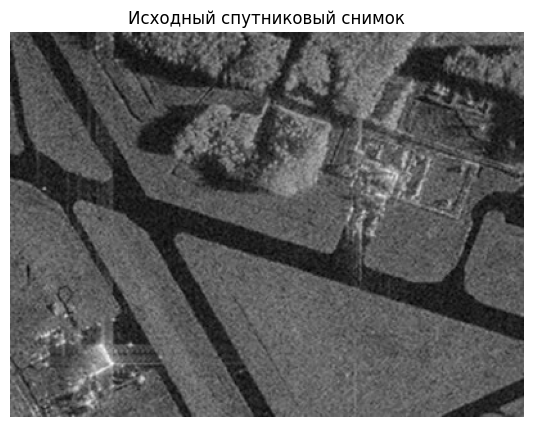

In [66]:
image_bgr = cv2.imread('sar_1.jpg')
if image_bgr is None:
    raise FileNotFoundError("Не найден файл sar_1.jpg. Поместите его рядом с ноутбуком.")
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 5))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходный спутниковый снимок')
plt.axis('off');


### Исходный критерий однородности

In [67]:
def homo_average(img, mask, point, T):
    """Исходный критерий: отличие от средней яркости текущего региона."""
    values = img[mask > 0]
    if values.size == 0:
        return True
    mean_value = float(values.mean())
    return abs(float(img[point]) - mean_value) <= T

def region_growing(img, seed_point, homo_fun, r=1, T=10):
    """Разрастание региона от seed_point=(строка, столбец)."""
    h, w = img.shape[:2]
    sy, sx = seed_point
    if not (0 <= sy < h and 0 <= sx < w):
        raise ValueError("Начальная точка находится за пределами изображения")
    mask = np.zeros((h, w), dtype=np.uint8)
    mask[sy, sx] = 1
    queue = deque([(sy, sx)])
    while queue:
        y, x = queue.popleft()
        for yy in range(max(0, y-r), min(h, y+r+1)):
            for xx in range(max(0, x-r), min(w, x+r+1)):
                if mask[yy, xx] == 0 and homo_fun(img, mask, (yy, xx), T):
                    mask[yy, xx] = 1
                    queue.append((yy, xx))
    return mask * 255


### Подбор параметров для выделения газона

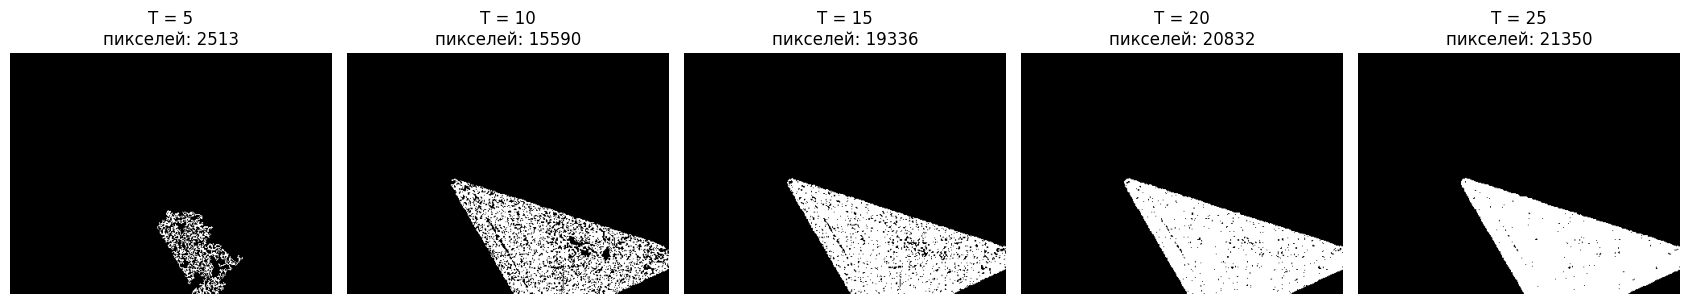

In [68]:
seed_point = (250, 250)
thresholds = [5, 10, 15, 20, 25]
fig, axes = plt.subplots(1, len(thresholds), figsize=(17, 4))
for ax, t in zip(axes, thresholds):
    result = region_growing(image_gray, seed_point, homo_average, r=1, T=t)
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"T = {t}\nпикселей: {np.count_nonzero(result)}")
    ax.axis("off")
plt.tight_layout();


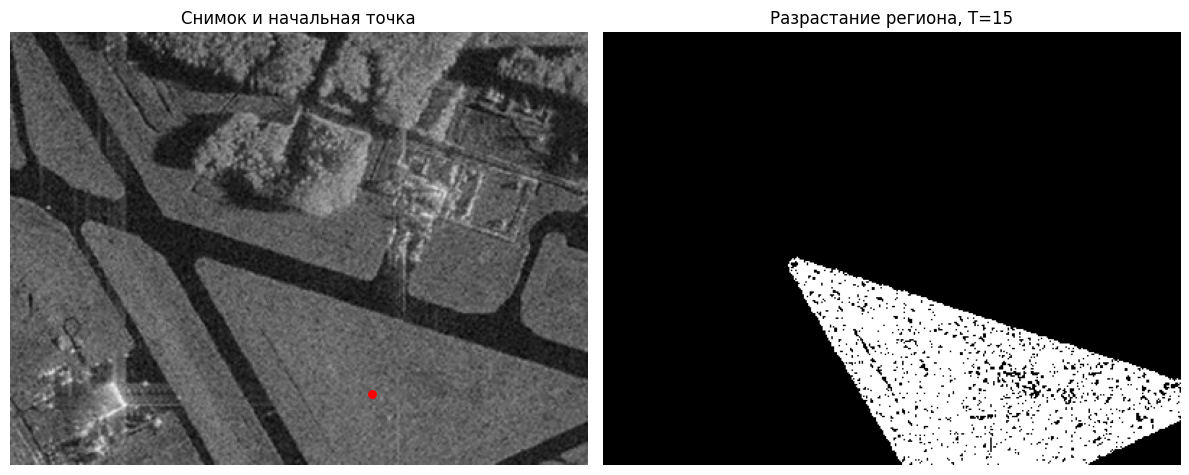

In [69]:
T_best = 15
mask_average = region_growing(image_gray, seed_point, homo_average, r=1, T=T_best)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.imshow(image_gray, cmap="gray"); plt.scatter([seed_point[1]], [seed_point[0]], c="red", s=30); plt.title("Снимок и начальная точка"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(mask_average, cmap="gray"); plt.title(f"Разрастание региона, T={T_best}"); plt.axis("off")
plt.tight_layout();


## 2. Альтернативный критерий однородности и сравнение

Критерий по среднему: 19336 пикселей
Локальный критерий: 119711 пикселей


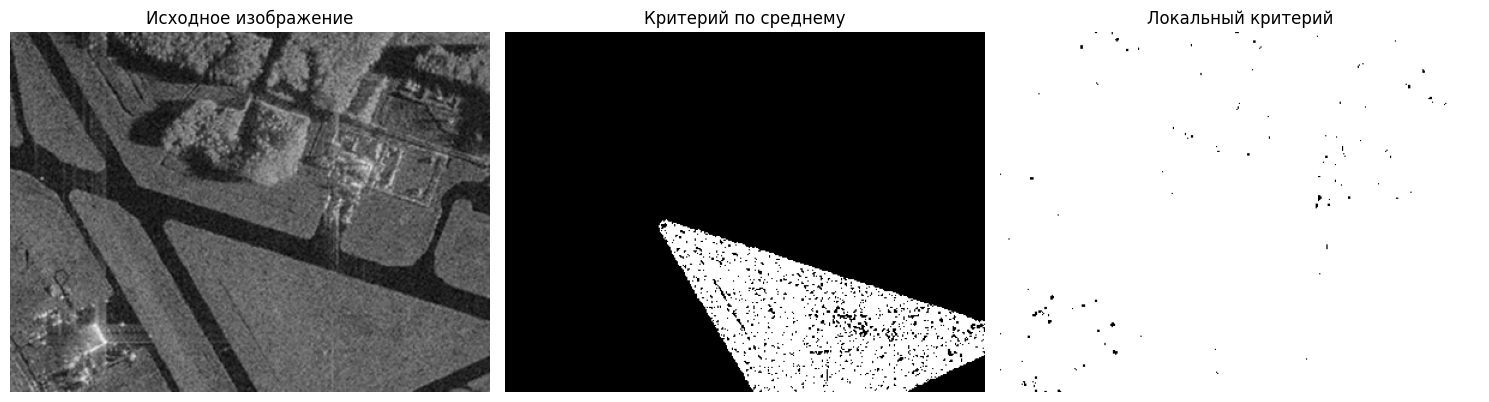

In [70]:
def homo_local(img, mask, point, T, r=1):
    """Альтернативный критерий: сравнение с яркостями выделенных соседей"""
    y, x = point
    y0, y1 = max(0, y-r), min(img.shape[0], y+r+1)
    x0, x1 = max(0, x-r), min(img.shape[1], x+r+1)
    local_mask = mask[y0:y1, x0:x1] > 0
    if not np.any(local_mask):
        return False
    local_values = img[y0:y1, x0:x1][local_mask].astype(float)
    return bool(np.min(np.abs(local_values - float(img[y, x]))) <= T)

def homo_local_adapter(img, mask, point, T):
    return homo_local(img, mask, point, T, r=1)

mask_local = region_growing(image_gray, seed_point, homo_local_adapter, r=1, T=T_best)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image_gray, cmap="gray"); axes[0].set_title("Исходное изображение")
axes[1].imshow(mask_average, cmap="gray"); axes[1].set_title("Критерий по среднему")
axes[2].imshow(mask_local, cmap="gray"); axes[2].set_title("Локальный критерий")
for ax in axes: ax.axis("off")
plt.tight_layout()
print(f"Критерий по среднему: {np.count_nonzero(mask_average)} пикселей")
print(f"Локальный критерий: {np.count_nonzero(mask_local)} пикселей")


## 3. Подсчёт пальм методом Watershed + Distance Transform

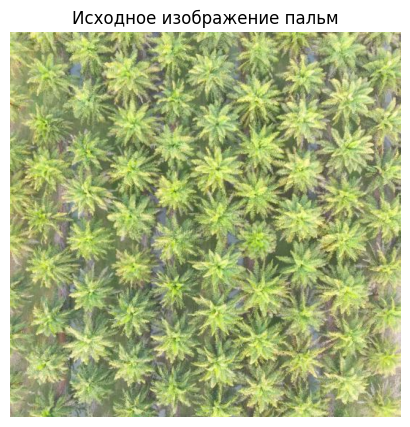

In [71]:
palm_bgr = cv2.imread('palm_1.jpg')
if palm_bgr is None:
    raise FileNotFoundError("Не найден palm_1.jpg.")
palm_gray = cv2.cvtColor(palm_bgr, cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(9, 5)); plt.imshow(cv2.cvtColor(palm_bgr, cv2.COLOR_BGR2RGB)); plt.title('Исходное изображение пальм'); plt.axis('off');


### Бинаризация и distance transform

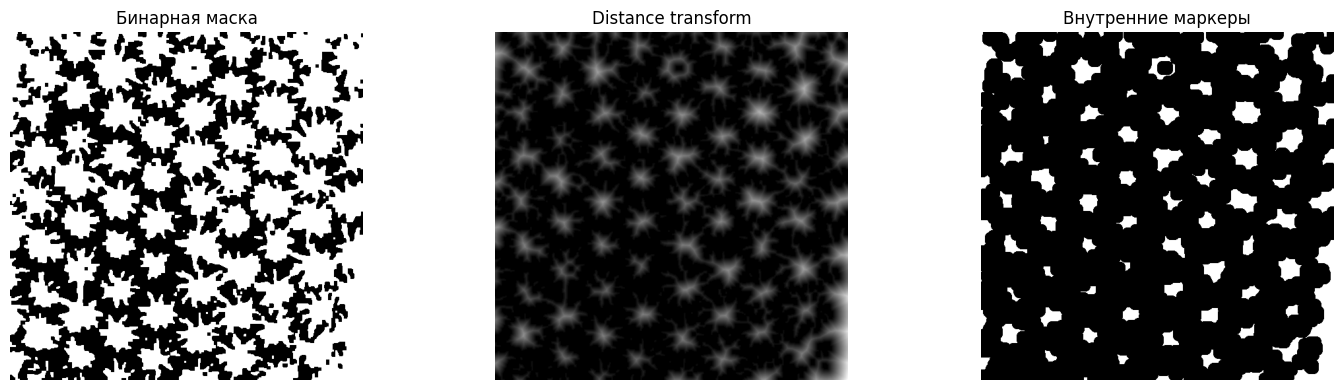

In [72]:
blur = cv2.GaussianBlur(palm_gray, (5, 5), 0)

_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

foreground_ratio = 0.25
_, sure_fg = cv2.threshold(dist, foreground_ratio * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

sure_bg = cv2.dilate(thresh, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(thresh, cmap="gray"); axes[0].set_title("Бинарная маска")
axes[1].imshow(dist, cmap="gray"); axes[1].set_title("Distance transform")
axes[2].imshow(sure_fg, cmap="gray"); axes[2].set_title("Внутренние маркеры")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

### Watershed, визуализация и подсчёт

Число найденных объектов-кандидатов: 86


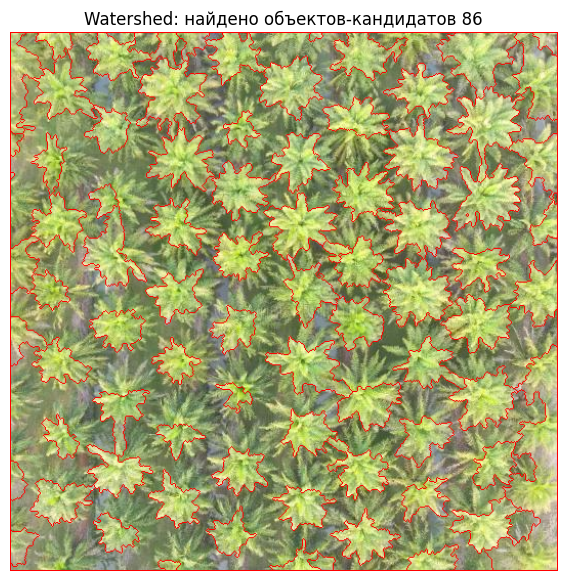

In [73]:
n_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
markers = cv2.watershed(palm_bgr.copy(), markers.astype(np.int32))

# Каждый отдельный положительный маркер, кроме фонового маркера 1, считаем объектом
object_ids = [int(v) for v in np.unique(markers) if v > 1]
count_palms = len(object_ids)

result_rgb = cv2.cvtColor(palm_bgr, cv2.COLOR_BGR2RGB)
result_rgb[markers == -1] = [255, 0, 0]
plt.figure(figsize=(12, 7)); plt.imshow(result_rgb); plt.title(f"Watershed: найдено объектов-кандидатов {count_palms}"); plt.axis("off");
print("Число найденных объектов-кандидатов:", count_palms)


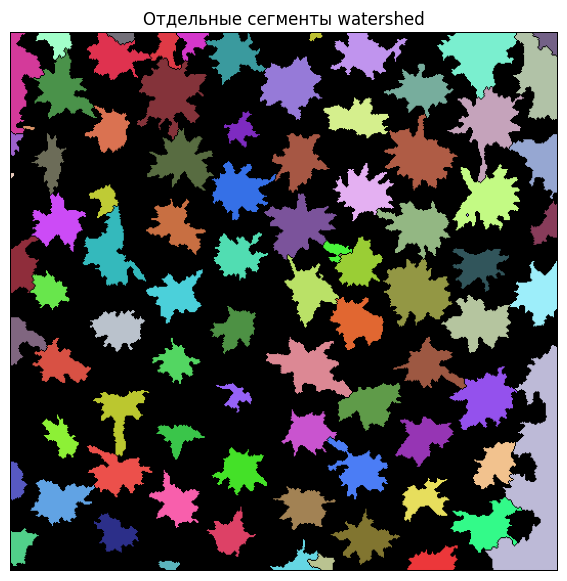

In [74]:
# Дополнительная проверка: вывести каждую область отдельным цветом.
colored = np.zeros_like(palm_bgr)
rng = np.random.default_rng(42)
for object_id in object_ids:
    colored[markers == object_id] = rng.integers(40, 256, size=3, dtype=np.uint8)
plt.figure(figsize=(12, 7)); plt.imshow(cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)); plt.title("Отдельные сегменты watershed"); plt.axis("off");
